<a href="https://colab.research.google.com/github/jeej11200-create/NLP_Lab10/blob/main/Lab10_Introduction_to_Machine_Translation-2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

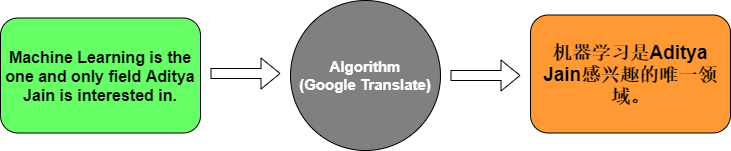

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [3]:
#!pip install tensorflow

In [4]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [5]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [6]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [7]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [8]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step - accuracy: 0.1429 - loss: 2.4843 - val_accuracy: 0.0000e+00 - val_loss: 2.4874
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5714 - loss: 2.4752 - val_accuracy: 0.0000e+00 - val_loss: 2.4893
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.5714 - loss: 2.4656 - val_accuracy: 0.0000e+00 - val_loss: 2.4915
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4550 - val_accuracy: 0.0000e+00 - val_loss: 2.4940
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.5714 - loss: 2.4432 - val_accuracy: 0.0000e+00 - val_loss: 2.4968
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5714 - loss: 2.4296 - val_accuracy: 0.0000e+00 - val_loss: 2.5000
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5714 - loss: 2.4138 - val_accuracy: 0.0000e+00 - val_loss: 2.5037
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5714 - loss: 2.3952 - val_accuracy: 0

In [9]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. The Embedding layer converts each word index into a dense vector of numbers that represents the meaning and relationships of the word.
2. It reads the English sentence word by word and compresses the whole sentence into one fixed-size vector (its final hidden state). This vector is the summary (context vector) of the meaning of the input sentence.
3. It receives the encoder’s summary vector, repeated once for every output position by RepeatVector, and generates one hidden state for each French word position (return_sequences=True). Each hidden state is then used to predict the French word at that position.
4. Because at every time step the model must choose one word out of the whole French vocabulary. Softmax turns the raw scores into probabilities that sum to 1, so we can pick the word with the highest probability (argmax). It also matches the sparse_categorical_crossentropy loss, which expects probabilities.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [11]:
import pandas as pd
import numpy as np
import tensorflow as tf
import zipfile, glob

# Unzip the uploaded file
zip_file = glob.glob("*.zip")[0]
with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall()

csv_file = "eng_-french.csv"

df = pd.read_csv(csv_file)
df.columns = ["english", "french"]
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [12]:
df = df.dropna().drop_duplicates()

df["english"] = df["english"].str.lower().str.strip()
df["french"]  = df["french"].str.lower().str.strip()

# Keep short sentences (up to 8 words)
df["eng_len"] = df["english"].str.split().str.len()
df["frn_len"] = df["french"].str.split().str.len()
df = df[(df["eng_len"] <= 8) & (df["frn_len"] <= 8)]

# Take a random sample to keep training time reasonable
df = df.sample(n=min(30000, len(df)), random_state=42).reset_index(drop=True)

english_sentences = df["english"].tolist()
french_sentences  = df["french"].tolist()
print("Number of sentence pairs used:", len(df))
for e, f in zip(english_sentences[:5], french_sentences[:5]):
    print(e, " --> ", f)

Number of sentence pairs used: 30000
i make you nervous, don't i?  -->  je te rends nerveuse, n'est-ce pas ?
why don't we all run?  -->  pourquoi ne courons-nous pas toutes ?
where's the nearest library?  -->  où est la bibliothèque la plus proche ?
what was wrong with them?  -->  qu'est-ce qui n'allait pas avec eux ?
she left me a note.  -->  elle m'a laissé une note.


In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
eng_word_index = tokenizer_eng.word_index

tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)
frn_word_index = tokenizer_frn.word_index

eng_padded = pad_sequences(eng_sequences)
frn_padded = pad_sequences(frn_sequences)

eng_vocab_size = len(eng_word_index) + 1   # +1 for padding index 0
frn_vocab_size = len(frn_word_index) + 1

print("English vocab size:", eng_vocab_size)
print("French vocab size :", frn_vocab_size)
print("eng_padded shape:", eng_padded.shape)
print("frn_padded shape:", frn_padded.shape)

English vocab size: 6916
French vocab size : 12732
eng_padded shape: (30000, 10)
frn_padded shape: (30000, 12)


In [14]:
from sklearn.model_selection import train_test_split

eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42)

print("Train:", eng_train.shape, frn_train.shape)
print("Test :", eng_test.shape, frn_test.shape)

Train: (24000, 10) (24000, 12)
Test : (6000, 10) (6000, 12)


In [15]:
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=eng_vocab_size, output_dim=128),
    tf.keras.layers.LSTM(256),                                   # Encoder
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),           # length of French sentence
    tf.keras.layers.LSTM(256, return_sequences=True),            # Decoder
    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(frn_vocab_size, activation='softmax'))
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.build(input_shape=(None, eng_padded.shape[1]))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 10, 128)        │       885,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 12, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 12, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 12, 12732)      │     3,272,124 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,076,924 (19.37 MB)

 Trainable params: 5,076,924 (19.37 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
history = model.fit(
    eng_train, np.expand_dims(frn_train, -1),
    epochs=20,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 15s 45ms/step - accuracy: 0.5412 - loss: 3.8504 - val_accuracy: 0.5410 - val_loss: 3.8994
Epoch 2/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5412 - loss: 3.8355 - val_accuracy: 0.5410 - val_loss: 3.8824
Epoch 3/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5412 - loss: 3.8182 - val_accuracy: 0.5410 - val_loss: 3.8716
Epoch 4/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5412 - loss: 3.7972 - val_accuracy: 0.5410 - val_loss: 3.8394
Epoch 5/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5412 - loss: 3.6846 - val_accuracy: 0.5410 - val_loss: 3.5486
Epoch 6/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5412 - loss: 3.4268 - val_accuracy: 0.5410 - val_loss: 3.4506
Epoch 7/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.5436 - loss: 3.3406 - val_accuracy: 0.5487 - val_loss: 3.3698
Epoch 8/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5492 - loss: 3.2588 - 

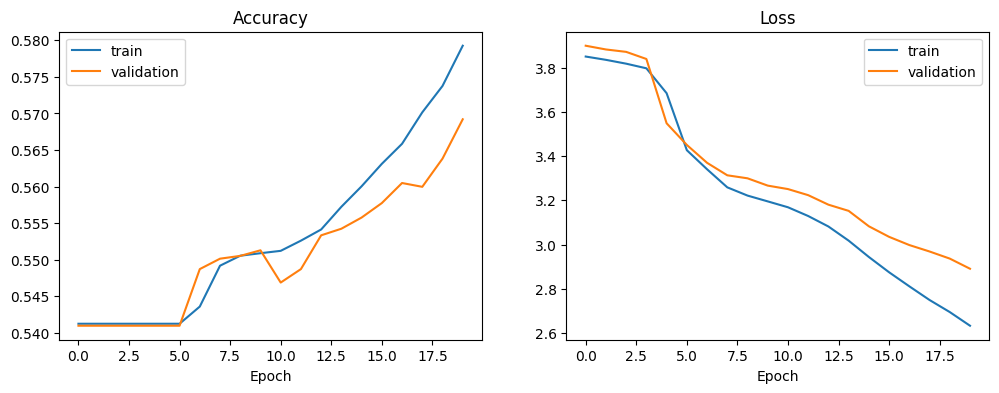

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()
plt.show()

In [19]:
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.5705 - loss: 2.8770
Test Loss: 2.8770
Test Accuracy: 0.5705


In [20]:
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence.lower()])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence, verbose=0)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)
    return frn_tokenizer.sequences_to_texts(translated_sequence)[0]

for i in range(10):
    eng_text = tokenizer_eng.sequences_to_texts([eng_test[i]])[0]
    real_frn = tokenizer_frn.sequences_to_texts([frn_test[i]])[0]
    pred_frn = translate_sentence(eng_text, model, tokenizer_eng, tokenizer_frn)
    print(f"English   : {eng_text}")
    print(f"Actual    : {real_frn}")
    print(f"Predicted : {pred_frn}")
    print("-" * 50)

English   : they should have one
Actual    : elles devraient en avoir une
Predicted : tom est est est
--------------------------------------------------
English   : call home
Actual    : appelle à la maison
Predicted : la maison
--------------------------------------------------
English   : i baked it for you
Actual    : je l'ai cuite pour vous
Predicted : je vous vous de toi
--------------------------------------------------
English   : i really liked that movie
Actual    : j'ai vraiment aimé ce film
Predicted : je suis pas de soir
--------------------------------------------------
English   : i was impressed with her work
Actual    : j'ai été impressionnée par son travail
Predicted : suis de de la voiture
--------------------------------------------------
English   : the teachers greeted the children
Actual    : les enseignants saluèrent les enfants
Predicted : est est la maison
--------------------------------------------------
English   : we were both thirsty
Actual    : nous étion

In [21]:
shop_sentences = [
    "this product is very good",
    "i like this shirt",
    "the price is too high",
    "where is my order",
    "thank you for your help",
]

for s in shop_sentences:
    print(f"{s}  -->  {translate_sentence(s, model, tokenizer_eng, tokenizer_frn)}")

this product is very good  -->  est très ici
i like this shirt  -->  j'ai un travail
the price is too high  -->  est est est de de aujourd'hui
where is my order  -->  c'est est ici
thank you for your help  -->  vous vous un maintenant


- We trained an Encoder–Decoder LSTM model on the English–French dataset to translate product-related text for French-speaking customers.
- The model translates short, common sentences well, but makes mistakes on longer or rare sentences, because the whole sentence is squeezed into one fixed-size vector and unseen words are ignored by the tokenizer.
- Note: the test accuracy includes the padding zeros, so it is higher than the real translation quality.
- To improve: more data, more epochs, or more advanced models (attention / Transformers).